In [2]:
from google.colab import files

uploaded = files.upload()

Saving archive (1).zip to archive (1).zip


In [3]:
import os
import zipfile

zip_path = '/content/archive (1).zip'
extract_path = '/content/lung_cancer_dataset'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Find the folder that directly contains all three class folders.
required_classes = {'Bengin cases', 'Malignant cases', 'Normal cases'}
dataset_dir = None

for root, dirs, files_in_folder in os.walk(extract_path):
    if required_classes.issubset(set(dirs)):
        dataset_dir = root
        break

if dataset_dir is None:
    raise FileNotFoundError(
        'Could not find the three class folders. '
        'Check that the correct dataset ZIP was uploaded.'
    )

print('Dataset folder:', dataset_dir)
for class_name in sorted(required_classes):
    class_path = os.path.join(dataset_dir, class_name)
    image_count = sum(
        1 for name in os.listdir(class_path)
        if name.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
    )
    print(class_name, ':', image_count, 'images')

Dataset folder: /content/lung_cancer_dataset/The IQ-OTHNCCD lung cancer dataset
Bengin cases : 120 images
Malignant cases : 561 images
Normal cases : 416 images


In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


In [6]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.20
)

train_data = datagen.flow_from_directory(
    dataset_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED
)

validation_data = datagen.flow_from_directory(
    dataset_dir,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=SEED
)

class_names = list(train_data.class_indices.keys())

print('Training class mapping:', train_data.class_indices)
print('Validation class mapping:', validation_data.class_indices)

Found 878 images belonging to 3 classes.
Found 219 images belonging to 3 classes.
Training class mapping: {'Bengin cases': 0, 'Malignant cases': 1, 'Normal cases': 2}
Validation class mapping: {'Bengin cases': 0, 'Malignant cases': 1, 'Normal cases': 2}


In [7]:
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_data.classes),
    y=train_data.classes
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        np.unique(train_data.classes),
        class_weights_array
    )
}

print('Class weights:', class_weights)

Class weights: {0: 3.048611111111111, 1: 0.651818856718634, 2: 0.8788788788788788}


In [8]:
# Load MobileNetV2 with ImageNet pretrained weights.
# Colab needs internet access to download these weights the first time.
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze pretrained layers for the first training stage.
base_model.trainable = False

cnn = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.30),
    layers.Dense(3, activation='softmax')
])

cnn.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [10]:
early_stop_head = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_head = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

history_head = cnn.fit(
    train_data,
    validation_data=validation_data,
    epochs=15,
    class_weight=class_weights,
    callbacks=[early_stop_head, reduce_lr_head]
)

Epoch 1/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.5672 - loss: 1.0783 - val_accuracy: 0.7169 - val_loss: 0.6553 - learning_rate: 1.0000e-04
Epoch 2/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.7836 - loss: 0.6012 - val_accuracy: 0.7215 - val_loss: 0.5744 - learning_rate: 1.0000e-04
Epoch 3/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.8292 - loss: 0.4874 - val_accuracy: 0.6849 - val_loss: 0.5996 - learning_rate: 1.0000e-04
Epoch 4/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.8565 - loss: 0.4120 - val_accuracy: 0.6758 - val_loss: 0.5947 - learning_rate: 1.0000e-04
Epoch 5/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.8770 - loss: 0.3765 - val_accuracy: 0.6804 - val_loss: 0.5680 - learning_rate: 5.0000e-05
Epoch 6/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.8770 - loss: 0.3776 - val_accuracy: 0.7032 - val_loss: 0.5460 - learning_rate: 5.0000e-05
Epoch 7/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.8884 - loss:

In [11]:
base_model.trainable = True

# Freeze most pretrained layers; fine-tune only the final portion.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for more stable fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_finetune = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_finetune = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-8
)

history_finetune = cnn.fit(
    train_data,
    validation_data=validation_data,
    epochs=15,
    class_weight=class_weights,
    callbacks=[early_stop_finetune, reduce_lr_finetune]
)

Epoch 1/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 105s 2s/step - accuracy: 0.9009 - loss: 0.3182 - val_accuracy: 0.7123 - val_loss: 0.5665 - learning_rate: 1.0000e-05
Epoch 2/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 71s 1s/step - accuracy: 0.9169 - loss: 0.2601 - val_accuracy: 0.7489 - val_loss: 0.6156 - learning_rate: 1.0000e-05
Epoch 3/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.9362 - loss: 0.1960 - val_accuracy: 0.7717 - val_loss: 0.6084 - learning_rate: 1.0000e-05
Epoch 4/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.9613 - loss: 0.1581 - val_accuracy: 0.7123 - val_loss: 0.7156 - learning_rate: 5.0000e-06
Epoch 5/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.9636 - loss: 0.1342 - val_accuracy: 0.7489 - val_loss: 0.6887 - learning_rate: 5.0000e-06
Epoch 6/15
55/55 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - accuracy: 0.9715 - loss: 0.1106 - val_accuracy: 0.7443 - val_loss: 0.6998 - learning_rate: 2.5000e-06


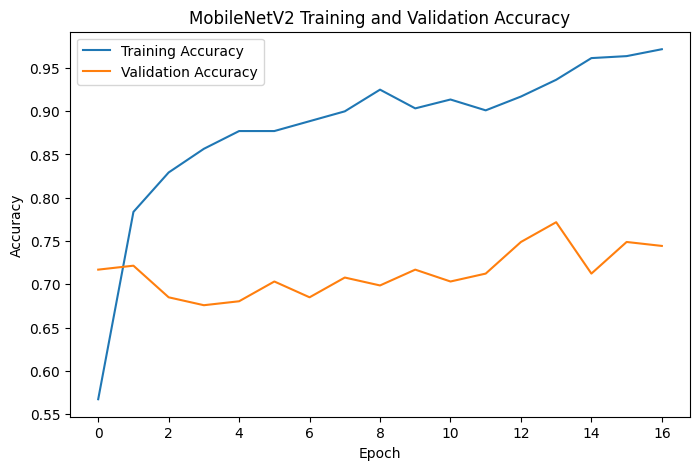

In [12]:
# Combine the two training stages for a single plot.
train_accuracy = history_head.history['accuracy'] + history_finetune.history['accuracy']
val_accuracy = history_head.history['val_accuracy'] + history_finetune.history['val_accuracy']

plt.figure(figsize=(8, 5))
plt.plot(train_accuracy, label='Training Accuracy')
plt.plot(val_accuracy, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('MobileNetV2 Training and Validation Accuracy')
plt.legend()
plt.show()

In [13]:
validation_loss, validation_accuracy = cnn.evaluate(
    validation_data,
    verbose=1
)

print('Validation Accuracy:', round(validation_accuracy * 100, 2), '%')
print('Validation Loss:', round(validation_loss, 4))

14/14 ━━━━━━━━━━━━━━━━━━━━ 12s 829ms/step - accuracy: 0.7123 - loss: 0.5665
Validation Accuracy: 71.23 %
Validation Loss: 0.5665


14/14 ━━━━━━━━━━━━━━━━━━━━ 13s 888ms/step
VALIDATION CLASSIFICATION REPORT
                 precision    recall  f1-score   support

   Bengin cases       0.15      0.29      0.20        24
Malignant cases       0.95      1.00      0.97       112
   Normal cases       0.69      0.45      0.54        83

       accuracy                           0.71       219
      macro avg       0.59      0.58      0.57       219
   weighted avg       0.76      0.71      0.72       219



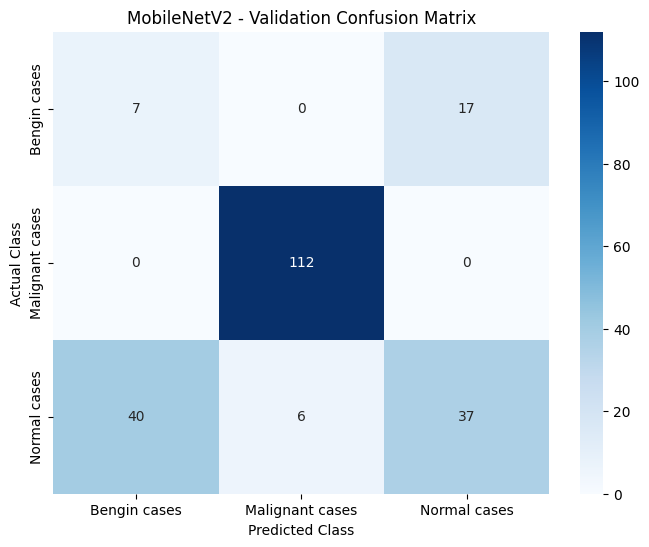

Predicted class counts:
Bengin cases : 47
Malignant cases : 118
Normal cases : 54


In [14]:
validation_data.reset()
val_probabilities = cnn.predict(validation_data, verbose=1)

y_pred = np.argmax(val_probabilities, axis=1)
y_true = validation_data.classes

print('VALIDATION CLASSIFICATION REPORT')
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('MobileNetV2 - Validation Confusion Matrix')
plt.show()

print('Predicted class counts:')
for i, name in enumerate(class_names):
    print(name, ':', int(np.sum(y_pred == i)))

In [15]:
def predict_lung_image(image_path):
    # Load and resize the image.
    test_img = image.load_img(
        image_path,
        target_size=IMAGE_SIZE
    )

    # Convert image to array and apply MobileNetV2 preprocessing.
    test_img = image.img_to_array(test_img)
    test_img = preprocess_input(test_img)
    test_img = np.expand_dims(test_img, axis=0)

    prediction = cnn.predict(test_img, verbose=0)[0]
    predicted_index = int(np.argmax(prediction))
    predicted_class = class_names[predicted_index]
    confidence = float(prediction[predicted_index]) * 100

    print('Predicted class:', predicted_class)
    print('Model confidence:', round(confidence, 2), '%')
    print('Class probabilities:')

    for class_name, probability in zip(class_names, prediction):
        print(f'{class_name}: {probability * 100:.2f}%')

    return predicted_class

In [26]:
# INPUT 1: Bengin case example
benign_image_path = input('Enter the image path for Bengin case: ')
predict_lung_image(benign_image_path)

Enter the image path for Bengin case: Bengin_case_image.jpg
Predicted class: Bengin cases
Model confidence: 84.56 %
Class probabilities:
Bengin cases: 84.56%
Malignant cases: 2.78%
Normal cases: 12.65%


'Bengin cases'

In [24]:
# INPUT 2: Malignant case example
malignant_image_path = input('Enter the image path for Malignant case: ')
predict_lung_image(malignant_image_path)

Enter the image path for Malignant case: Malignant_image.jpg
Predicted class: Malignant cases
Model confidence: 99.05 %
Class probabilities:
Bengin cases: 0.44%
Malignant cases: 99.05%
Normal cases: 0.51%


'Malignant cases'

In [27]:
# INPUT 3: Normal case example
normal_image_path = input('Enter the image path for Normal case: ')
predict_lung_image(normal_image_path)

Enter the image path for Normal case: Normal_image.jpg
Predicted class: Normal cases
Model confidence: 60.02 %
Class probabilities:
Bengin cases: 36.90%
Malignant cases: 3.08%
Normal cases: 60.02%


'Normal cases'

In [28]:
cnn.save('/content/Lung_Cancer_Prediction_Using_CNN_MobileNetV2.keras')
print('MobileNetV2 model saved successfully.')

MobileNetV2 model saved successfully.
